In [3]:
!pip install ucimlrepo xgboost

Defaulting to user installation because normal site-packages is not writeable


In [4]:
# Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
            roc_auc_score,confusion_matrix,classification_report,roc_curve)

import warnings
warnings.filterwarnings("ignore")

In [5]:
# load the dataset
breast_cancer = fetch_ucirepo(id=17)

# Features
X = breast_cancer.data.features

# Target
y = breast_cancer.data.targets

print("Dataset successfully loaded!")

print("Features shape:", X.shape)
print("Target shape:", y.shape)
X.head()
y.head()


Dataset successfully loaded!
Features shape: (569, 30)
Target shape: (569, 1)


,Diagnosis
0,M
1,M
2,M
3,M
4,M


In [6]:
# Combine features and target
data = pd.concat([X, y], axis=1)
display(data.head())

print("Rows:", data.shape[0])
print("Columns:", data.shape[1])


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


Rows: 569
Columns: 31


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavit

In [8]:
# Chaeck for mising value 
print(data.isnull().sum())

radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
Diagnosis             0
dtype: int64


In [9]:
# Check for duplicate records
data.duplicated().sum()

# if exist drop it 
data = data.drop_duplicates()

In [10]:
# Features and Target
X = data.drop("Diagnosis", axis=1)
y = data["Diagnosis"]

In [11]:
# Convert target into numerical values
# B → 0 (Benign)
# M → 1 (Malignant)
y = y.map({'B': 0, 'M': 1})
print(y.head())

0    1
1    1
2    1
3    1
4    1
Name: Diagnosis, dtype: int64


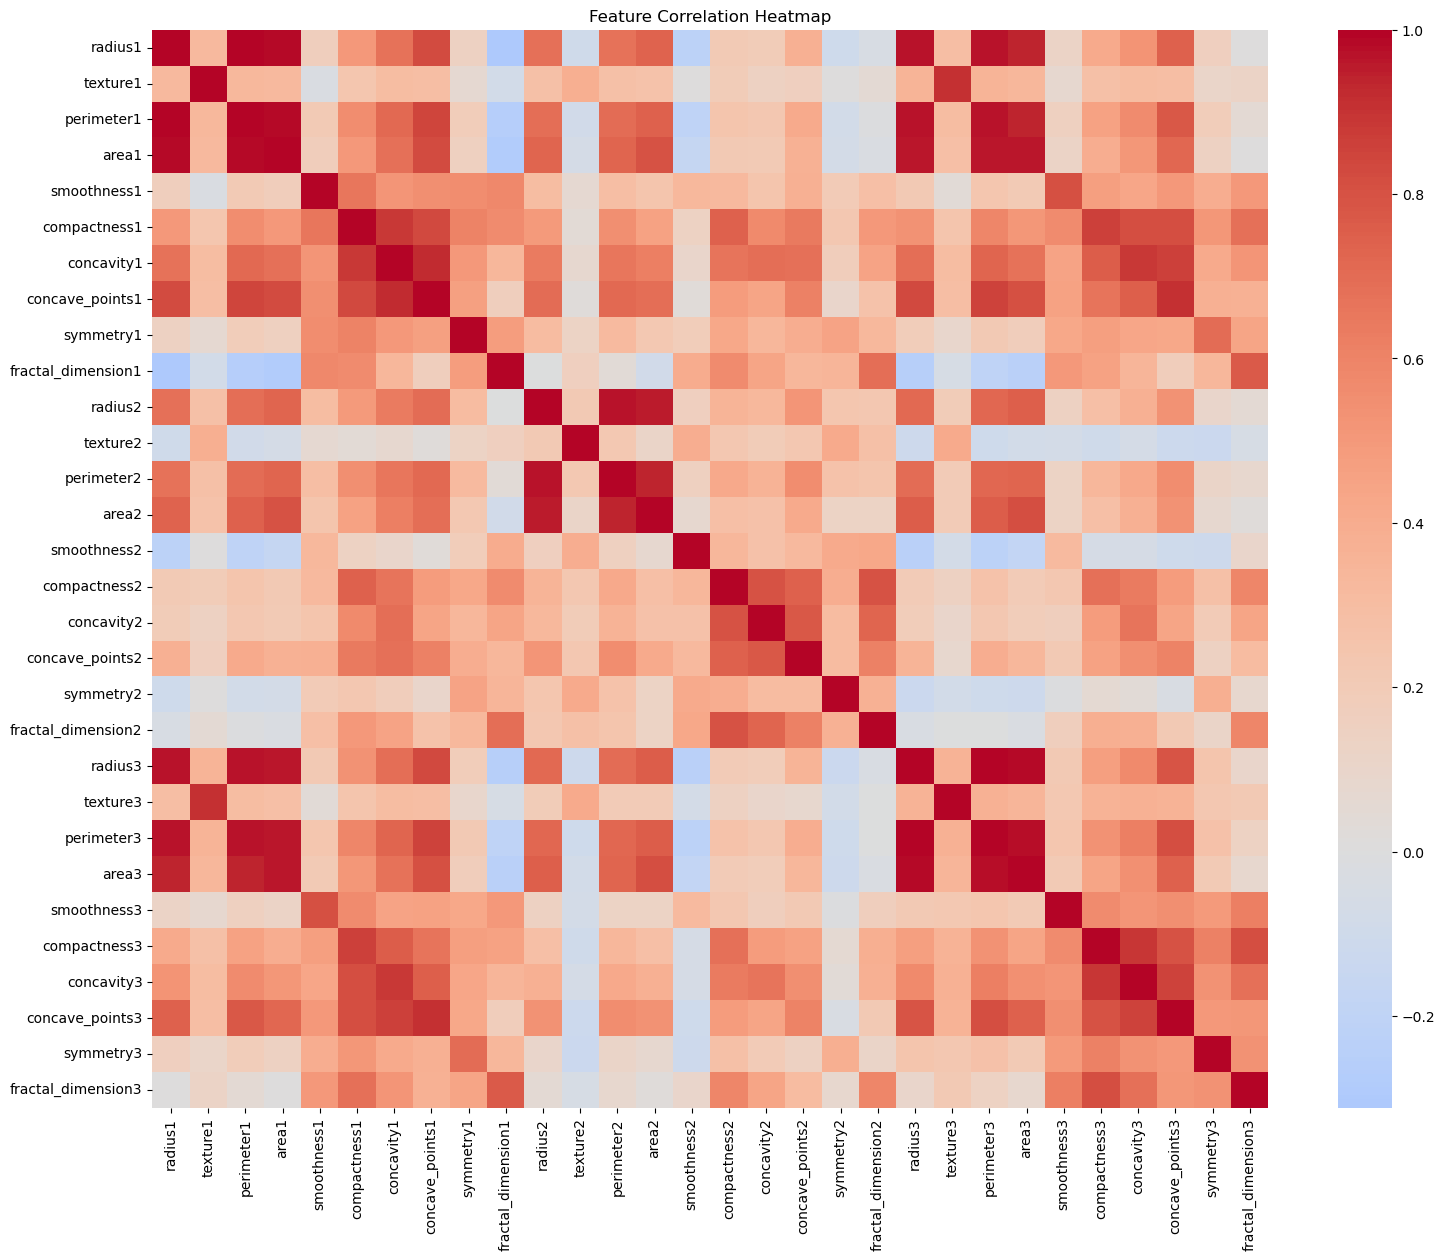

In [12]:
# Feature correlation
plt.figure(figsize=(18,14))
sns.heatmap(X.corr(),cmap="coolwarm",center=0)

plt.title("Feature Correlation Heatmap")
plt.show()

In [13]:
#Train and Test Split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,
                                                    random_state=42,stratify=y)


In [14]:
# Logistic Regression
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000))])

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [15]:
# Evaluate - Logistic Regression
print("Logistic Regression")
print("Accuracy:",accuracy_score(y_test, y_pred_lr))
print("Precision:",precision_score(y_test, y_pred_lr))
print("Recall:",recall_score(y_test, y_pred_lr))
print("F1 Score:",f1_score(y_test, y_pred_lr))
print("ROC-AUC:",roc_auc_score(y_test, y_prob_lr))

Logistic Regression
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219
ROC-AUC: 0.996031746031746


In [16]:
# SVM 
svm_model = Pipeline([('scaler', StandardScaler()),('model', 
                                SVC(kernel='rbf',probability=True,random_state=42))])

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

In [17]:
# SVM Evaluate
print("Support Vector Machine")
print("Accuracy:",accuracy_score(y_test, y_pred_svm))
print("Precision:",precision_score(y_test, y_pred_svm))
print("Recall:",recall_score(y_test, y_pred_svm))
print("F1 Score:",f1_score(y_test, y_pred_svm))
print("ROC-AUC:",roc_auc_score(y_test, y_prob_svm))

Support Vector Machine
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629
ROC-AUC: 0.9947089947089947


In [18]:
# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,random_state=42,class_weight='balanced')

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [19]:
# Evaluate - Random Forest
print("Random Forest")
print("Accuracy:",accuracy_score(y_test, y_pred_rf))
print("Precision:",precision_score(y_test, y_pred_rf))
print("Recall:",recall_score(y_test, y_pred_rf))
print("F1 Score:",f1_score(y_test, y_pred_rf))
print("ROC-AUC:",roc_auc_score(y_test, y_prob_rf))

Random Forest
Accuracy: 0.9649122807017544
Precision: 1.0
Recall: 0.9047619047619048
F1 Score: 0.95
ROC-AUC: 0.9970238095238095


In [20]:
# XGBoost
xgb_model = XGBClassifier(n_estimators=300,learning_rate=0.05,max_depth=4,
                          subsample=0.8,colsample_bytree=0.8,eval_metric='logloss',random_state=42)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [21]:
# Evaluate - XGBoost 
print("XGBoost")
print("Accuracy:",accuracy_score(y_test, y_pred_xgb))
print("Precision:",precision_score(y_test, y_pred_xgb))
print("Recall:",recall_score(y_test, y_pred_xgb))
print("F1 Score:",f1_score(y_test, y_pred_xgb))
print("ROC-AUC:",roc_auc_score(y_test, y_prob_xgb))

XGBoost
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629
ROC-AUC: 0.9920634920634921


In [22]:
# Comparing the Models
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_svm),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.964912,0.975,0.928571,0.951220,0.996032
1,SVM,0.973684,1.000,0.928571,0.962963,0.994709
2,Random Forest,0.964912,1.000,0.904762,0.950000,0.997024
3,XGBoost,0.973684,1.000,0.928571,0.962963,0.992063


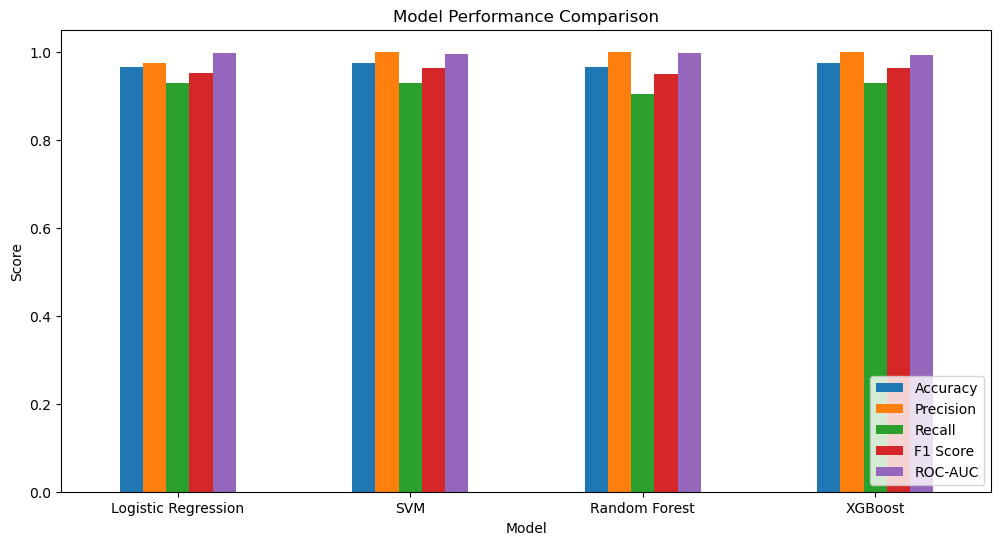

In [23]:
# Visualize Model Comparision
results.set_index('Model')[['Accuracy','Precision','Recall','F1 Score','ROC-AUC']].plot(
    kind='bar',figsize=(12,6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

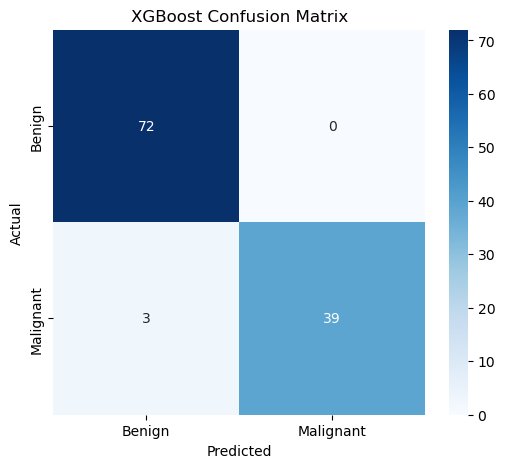

In [24]:
# Confusion Matrix - XGBoost
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6,5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
            xticklabels=['Benign', 'Malignant'],yticklabels=['Benign', 'Malignant'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.show()


In [25]:
# Understand TP, TN, FP and FN
tn, fp, fn, tp = confusion_matrix(y_test,y_pred_xgb).ravel()

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

True Negative : 72
False Positive: 0
False Negative: 3
True Positive : 39


In [26]:
# Classification Report
print(classification_report(y_test,y_pred_xgb,target_names=['Benign', 'Malignant']))

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



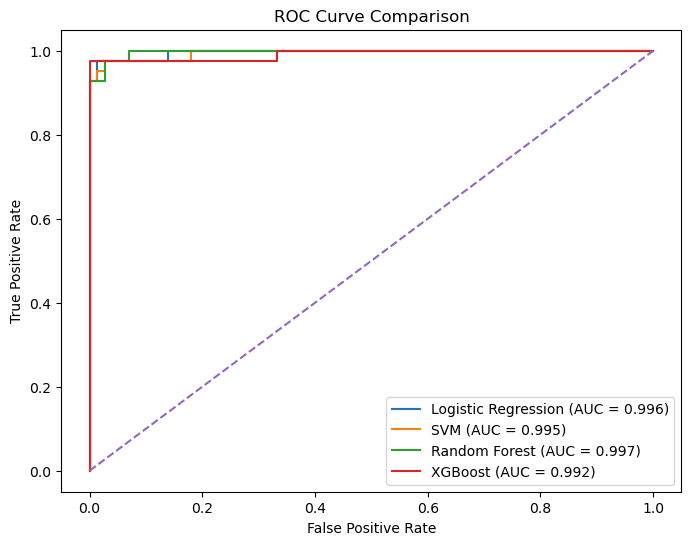

In [27]:
# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8,6))

plt.plot(fpr_lr,tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.3f})")

plt.plot(fpr_svm,tpr_svm,
    label=f"SVM (AUC = {roc_auc_score(y_test, y_prob_svm):.3f})")

plt.plot(fpr_rf,tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})")

plt.plot(fpr_xgb,tpr_xgb,
    label=f"XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.3f})")

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [31]:
# K-Fold Cross Validation
kcv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

# Logistic Regression
lr_cv = cross_val_score(logistic_model,X,y,cv=kcv,scoring='accuracy')

print("Logistic Regression CV scores:")
print(lr_cv)
print("Mean:", lr_cv.mean())

# SVM
svm_cv = cross_val_score(svm_model,X,y,cv=kcv,scoring='accuracy')

print("\n SVM CV scores:")
print(svm_cv)
print("Mean:", svm_cv.mean())

# Random forest
rf_cv = cross_val_score(rf_model,X,y,cv=kcv,scoring='accuracy')

print("\n Random Forest CV scores:")
print(rf_cv)
print("Mean:", rf_cv.mean())

# XGBoost
xgb_cv = cross_val_score(xgb_model,X,y,cv=kcv,scoring='accuracy')

print("\n XGBoost CV scores:")
print(xgb_cv)
print("Mean:", xgb_cv.mean())

Logistic Regression CV scores:
[0.97368421 0.94736842 0.96491228 0.99122807 0.99115044]
Mean: 0.9736686849868033

 SVM CV scores:
[0.99122807 0.94736842 0.97368421 0.99122807 0.98230088]
Mean: 0.9771619313771154

 Random Forest CV scores:
[0.97368421 0.94736842 0.96491228 0.95614035 0.96460177]
Mean: 0.9613414066138798

 XGBoost CV scores:
[1.         0.94736842 0.95614035 0.95614035 0.97345133]
Mean: 0.9666200900481291


In [29]:
# New Prediction 
sample = X_test.iloc[[0]]

prediction = xgb_model.predict(sample)[0]
probability = xgb_model.predict_proba(sample)[0][1]

if prediction == 1:
    result = "Malignant"
else:
    result = "Benign"

print("Predicted Class:", result)
print("Model probability of malignant class:",round(probability * 100, 2), "%")

Predicted Class: Benign
Model probability of malignant class: 0.13 %
